In [ ]:
!pip install -q scikit-image PyWavelets xgboost scikit-learn opencv-python-headless matplotlib seaborn pandas numpy scipy
print("✅ Tüm paketler kuruldu.")

✅ Tüm paketler kuruldu.


In [ ]:
import os, time, copy, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy import stats
import pywt
from skimage.feature import hog, local_binary_pattern
from skimage.feature import graycomatrix, graycoprops
from skimage import exposure
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier
from matplotlib.patches import Patch

SEED = 42
np.random.seed(SEED)
print(f"✅ NumPy        : {np.__version__}")
print(f"✅ Scikit-learn : {__import__('sklearn').__version__}")
print(f"✅ Scikit-image : {__import__('skimage').__version__}")
print(f"✅ PyWavelets   : {pywt.__version__}")
print(f"✅ XGBoost      : {__import__('xgboost').__version__}")
print(f"✅ OpenCV       : {cv2.__version__}")

✅ NumPy        : 2.0.2
✅ Scikit-learn : 1.6.1
✅ Scikit-image : 0.25.2
✅ PyWavelets   : 1.8.0
✅ XGBoost      : 3.2.0
✅ OpenCV       : 4.13.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SPLIT_DIR = "/content/drive/MyDrive/Colab Notebooks/Veri/paddydoc_split"
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "validation")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

OUTPUT_DIR   = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3"
FEATURES_DIR = os.path.join(OUTPUT_DIR, "features")
FIGURES_DIR  = os.path.join(OUTPUT_DIR, "figures")
RESULTS_DIR  = os.path.join(OUTPUT_DIR, "results")
for d in [FEATURES_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

IMG_SIZE = (128, 128)
N_FOLDS  = 5
CLASS_NAMES = sorted([d for d in os.listdir(TRAIN_DIR)
                      if os.path.isdir(os.path.join(TRAIN_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)

print("📁 Veri Seti Kontrolü:")
total = 0
for split, path in [("train", TRAIN_DIR), ("validation", VAL_DIR), ("test", TEST_DIR)]:
    s = 0
    for cls in CLASS_NAMES:
        cp = os.path.join(path, cls)
        n = len([f for f in os.listdir(cp) if f.lower().endswith(('.bmp','.jpg','.jpeg','.png'))]) if os.path.exists(cp) else 0
        s += n; total += n
    print(f"  {split:<11}: {s}")
print(f"\n✅ Sınıflar: {NUM_CLASSES} → {CLASS_NAMES}")
print(f"✅ Toplam: {total} | Çıktı: {OUTPUT_DIR}")

Mounted at /content/drive
📁 Veri Seti Kontrolü:
  train      : 2240
  validation : 320
  test       : 640

✅ Sınıflar: 10 → ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']
✅ Toplam: 3200 | Çıktı: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3


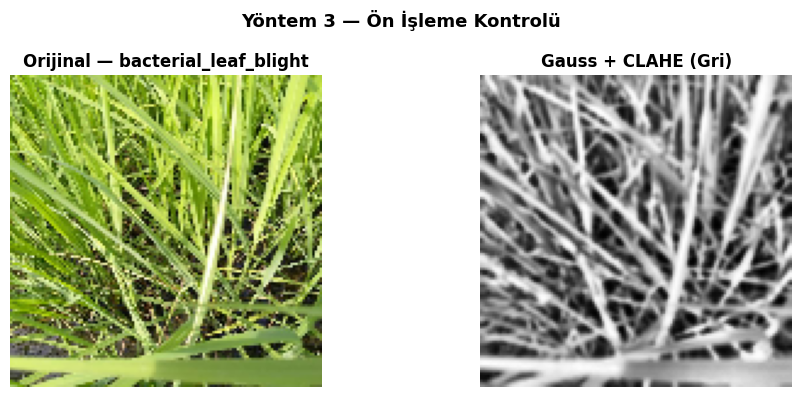

✅ Shape: (128, 128)  dtype: uint8


In [ ]:
def preprocess_gray(img_bgr, img_size=(128,128)):
    gray     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    resized  = cv2.resize(gray, img_size, interpolation=cv2.INTER_AREA)
    blurred  = cv2.GaussianBlur(resized, (3,3), 0)
    clahe    = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    return clahe.apply(blurred)  # uint8 H×W

# Görsel kontrol
sp = os.path.join(TRAIN_DIR, CLASS_NAMES[0])
sf = os.path.join(sp, sorted(os.listdir(sp))[0])
raw = cv2.imread(sf)
proc = preprocess_gray(raw, IMG_SIZE)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].imshow(cv2.cvtColor(cv2.resize(raw, IMG_SIZE), cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Orijinal — {CLASS_NAMES[0]}", fontweight='bold'); axes[0].axis('off')
axes[1].imshow(proc, cmap='gray')
axes[1].set_title("Gauss + CLAHE (Gri)", fontweight='bold'); axes[1].axis('off')
plt.suptitle("Yöntem 3 — Ön İşleme Kontrolü", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR,"Yontem3_onisleme.png"), dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Shape: {proc.shape}  dtype: {proc.dtype}")

In [ ]:
def load_gray_images(directory, img_size=(128,128)):
    images, labels = [], []
    for ci, cn in enumerate(CLASS_NAMES):
        cp = os.path.join(directory, cn)
        if not os.path.isdir(cp): continue
        for fname in sorted([f for f in os.listdir(cp) if f.lower().endswith(('.bmp','.jpg','.jpeg','.png'))]):
            img = cv2.imread(os.path.join(cp, fname))
            if img is None: continue
            images.append(preprocess_gray(img, img_size))
            labels.append(ci)
    return images, labels

print("⏳ Görüntüler yükleniyor...")
t0 = time.time()
a,b = load_gray_images(TRAIN_DIR, IMG_SIZE)
c,d = load_gray_images(VAL_DIR,   IMG_SIZE)
e,f = load_gray_images(TEST_DIR,  IMG_SIZE)
X_gray_all = a+c+e
y_all = np.array(b+d+f, dtype=np.int32)
sidx = np.random.RandomState(SEED).permutation(len(X_gray_all))
X_gray_all = [X_gray_all[i] for i in sidx]
y_all = y_all[sidx]
print(f"✅ Yükleme ({time.time()-t0:.1f}s) | Toplam: {len(X_gray_all)}")
for i,cn in enumerate(CLASS_NAMES): print(f"  {cn:<26}: {np.sum(y_all==i)}")

⏳ Görüntüler yükleniyor...
✅ Yükleme (373.0s) | Toplam: 3200
  bacterial_leaf_blight     : 320
  bacterial_leaf_streak     : 320
  bacterial_panicle_blight  : 320
  blast                     : 320
  brown_spot                : 320
  dead_heart                : 320
  downy_mildew              : 320
  hispa                     : 320
  normal                    : 320
  tungro                    : 320


In [ ]:
# ═══ BAŞLIK 1 — Şekil: Hu Moments ═══════════════════════════
def extract_hu_moments(img):
    """7 döndürme+ölçek değişmez Hu momenti. Log-normalize."""
    hu = cv2.HuMoments(cv2.moments(img)).flatten()
    return (-np.sign(hu) * np.log10(np.abs(hu)+1e-10)).astype(np.float32)  # 7

# ═══ BAŞLIK 2 — Doku: GLCM ═══════════════════════════════════
def extract_glcm(img):
    """4 yön × 6 GLCM özelliği = 24 boyut."""
    imgq  = (img // 16).astype(np.uint8)
    glcm  = graycomatrix(imgq, [1], [0,np.pi/4,np.pi/2,3*np.pi/4], levels=16, symmetric=True, normed=True)
    feats = []
    for prop in ['contrast','dissimilarity','homogeneity','energy','correlation','ASM']:
        feats.extend(graycoprops(glcm, prop).flatten())
    return np.array(feats, dtype=np.float32)  # 24

# ═══ BAŞLIK 3 — Gradyan/Kenar: HOG ══════════════════════════
def extract_hog(img):
    """orientations=9, ppc=(8,8), cpb=(2,2) — 128×128 → ~1764 boyut."""
    return hog(img, orientations=9, pixels_per_cell=(8,8),
               cells_per_block=(2,2), block_norm='L2-Hys',
               visualize=False, feature_vector=True).astype(np.float32)

# ═══ BAŞLIK 4 — Yerel Örüntü: LBP ══════════════════════════
def extract_lbp(img, P=8, R=1.0):
    """P=8, R=1, uniform → 10 bin normalize histogram."""
    lbp = local_binary_pattern(img, P=P, R=R, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=P+2, range=(0,P+2), density=True)
    return hist.astype(np.float32)  # 10

# ═══ BAŞLIK 5 — Frekans/Dönüşüm: Wavelet ════════════════════
def extract_wavelet(img):
    """Haar 2 seviye → LL2: mean, std, energy, entropy (4 boyut)."""
    f = img.astype(np.float32)
    LL1,(_, _,_) = pywt.dwt2(f,'haar')
    LL2,(_, _,_) = pywt.dwt2(LL1,'haar')
    flat = LL2.flatten()
    h,_ = np.histogram(flat, bins=64, density=True); h+=1e-10
    return np.array([np.mean(flat),np.std(flat),
                     np.sum(flat**2)/len(flat),-np.sum(h*np.log2(h))],
                    dtype=np.float32)  # 4

# ═══ BAŞLIK 6 — İstatistiksel: Piksel + Canny ════════════════
def extract_statistical(img):
    """mean, std, skewness, kurtosis (4 boyut)."""
    flat = img.flatten().astype(np.float64)
    return np.array([np.mean(flat),np.std(flat),
                     float(stats.skew(flat)),float(stats.kurtosis(flat))],
                    dtype=np.float32)  # 4

def extract_canny_stats(img, low=50, high=150):
    """Canny kenar istatistikleri: oran, mean, std, norm_count (4 boyut)."""
    edges = cv2.Canny(img, low, high)
    tp = img.shape[0]*img.shape[1]
    mask = edges>0
    cnt  = int(np.sum(mask))
    em = float(np.mean(img[mask])) if cnt>0 else 0.0
    es = float(np.std(img[mask]))  if cnt>0 else 0.0
    return np.array([cnt/tp, em, es, cnt/tp], dtype=np.float32)  # 4

# ── Boyut testi ──
_t = X_gray_all[0]
_hu=extract_hu_moments(_t); _gl=extract_glcm(_t); _hg=extract_hog(_t)
_lb=extract_lbp(_t);        _wv=extract_wavelet(_t)
_st=extract_statistical(_t); _cn=extract_canny_stats(_t)
FE_DIMS = {
    'Hu Moments (Şekil)'  : _hu.shape[0],
    'GLCM (Doku)'         : _gl.shape[0],
    'HOG (Gradyan/Kenar)' : _hg.shape[0],
    'LBP (Yerel Örüntü)'  : _lb.shape[0],
    'Wavelet (Frekans)'   : _wv.shape[0],
    'Piksel İstatistik'   : _st.shape[0],
    'Canny İstatistik'    : _cn.shape[0],
}
total_dim=0
print("✅ FE Fonksiyonları Boyut Testi:")
for n,dd in FE_DIMS.items():
    print(f"  {n:<28}: {dd:>6} boyut")
    total_dim+=dd
print(f"  {'TOPLAM':<28}: {total_dim:>6} boyut")

✅ FE Fonksiyonları Boyut Testi:
  Hu Moments (Şekil)          :      7 boyut
  GLCM (Doku)                 :     24 boyut
  HOG (Gradyan/Kenar)         :   8100 boyut
  LBP (Yerel Örüntü)          :     10 boyut
  Wavelet (Frekans)           :      4 boyut
  Piksel İstatistik           :      4 boyut
  Canny İstatistik            :      4 boyut
  TOPLAM                      :   8153 boyut


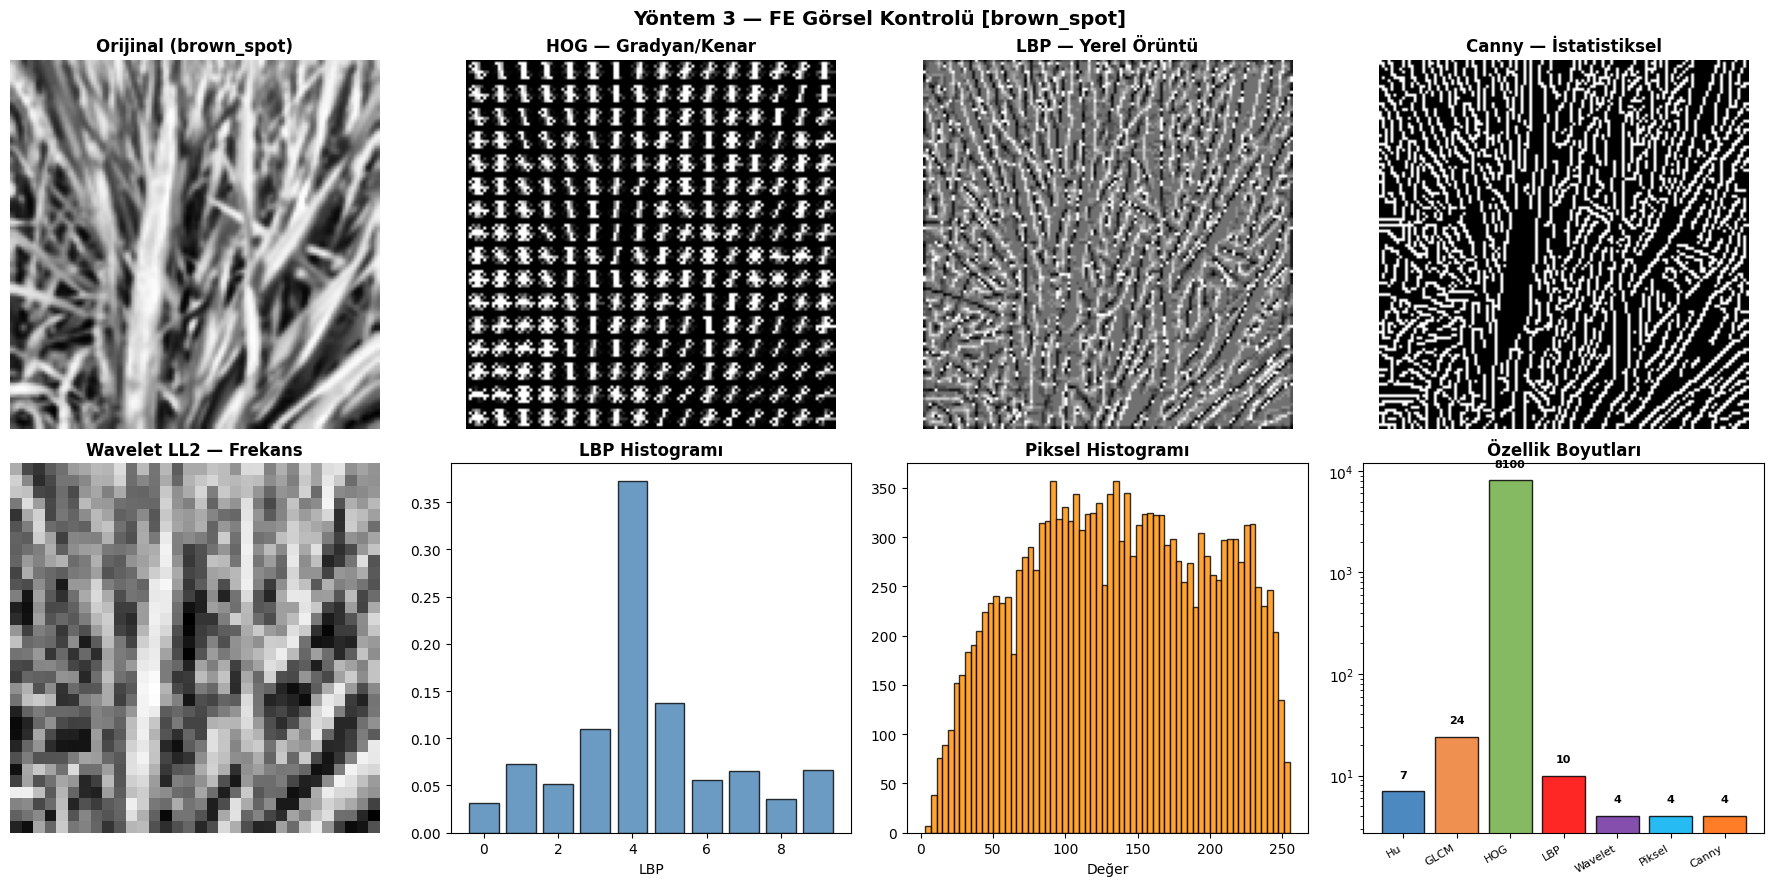

💾 FE görsel kaydedildi.


In [ ]:
demo = X_gray_all[0]
demo_lbl = CLASS_NAMES[int(y_all[0])]
hog_feat, hog_vis = hog(demo,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm='L2-Hys',visualize=True,feature_vector=True)
hog_vis_r = exposure.rescale_intensity(hog_vis, in_range=(0,10))
lbp_img = local_binary_pattern(demo, P=8, R=1, method='uniform')
canny_img = cv2.Canny(demo, 50, 150)
LL1,_ = pywt.dwt2(demo.astype(np.float32),'haar')
LL2,_ = pywt.dwt2(LL1,'haar')
fig, axes = plt.subplots(2, 4, figsize=(18,9))
fig.suptitle(f"Yöntem 3 — FE Görsel Kontrolü [{demo_lbl}]", fontsize=14, fontweight='bold')
axes[0,0].imshow(demo,cmap='gray'); axes[0,0].set_title(f"Orijinal ({demo_lbl})",fontweight='bold'); axes[0,0].axis('off')
axes[0,1].imshow(hog_vis_r,cmap='gray'); axes[0,1].set_title("HOG — Gradyan/Kenar",fontweight='bold'); axes[0,1].axis('off')
axes[0,2].imshow(lbp_img,cmap='gray'); axes[0,2].set_title("LBP — Yerel Örüntü",fontweight='bold'); axes[0,2].axis('off')
axes[0,3].imshow(canny_img,cmap='gray'); axes[0,3].set_title("Canny — İstatistiksel",fontweight='bold'); axes[0,3].axis('off')
axes[1,0].imshow(LL2,cmap='gray'); axes[1,0].set_title("Wavelet LL2 — Frekans",fontweight='bold'); axes[1,0].axis('off')
n_bins=10; lh,_=np.histogram(lbp_img.ravel(),bins=n_bins,range=(0,n_bins),density=True)
axes[1,1].bar(range(n_bins),lh,color='steelblue',edgecolor='black',alpha=0.8)
axes[1,1].set_title("LBP Histogramı",fontweight='bold'); axes[1,1].set_xlabel("LBP")
axes[1,2].hist(demo.flatten(),bins=64,color='darkorange',alpha=0.8,edgecolor='black')
axes[1,2].set_title("Piksel Histogramı",fontweight='bold'); axes[1,2].set_xlabel("Değer")
cb=['#2E75B6','#ED7D31','#70AD47','#FF0000','#7030A0','#00B0F0','#FF6600']
fn=list(FE_DIMS.keys()); fv=list(FE_DIMS.values())
axes[1,3].bar(range(len(fn)),fv,color=cb,alpha=0.85,edgecolor='black')
axes[1,3].set_xticks(range(len(fn))); axes[1,3].set_xticklabels([n.split(' ')[0] for n in fn],rotation=30,ha='right',fontsize=8)
axes[1,3].set_title("Özellik Boyutları",fontweight='bold'); axes[1,3].set_yscale('log')
for j,(n,v) in enumerate(zip(fn,fv)): axes[1,3].text(j,v*1.3,str(v),ha='center',va='bottom',fontsize=8,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR,"Yontem3_fe_gorsel.png"),dpi=150,bbox_inches='tight')
plt.show(); print("💾 FE görsel kaydedildi.")

In [ ]:
FEAT_PATH = os.path.join(FEATURES_DIR,"Yontem3_features_handcrafted.npy")
LBL_PATH  = os.path.join(FEATURES_DIR,"Yontem3_labels.npy")
if os.path.exists(FEAT_PATH):
    print(f"⏭️  Mevcut: {FEAT_PATH}")
    X_features = np.load(FEAT_PATH)
    y_labels   = np.load(LBL_PATH)
    print(f"   Yüklendi → X: {X_features.shape}  y: {y_labels.shape}")
else:
    print("="*60)
    print("  Özellik Çıkarımı Başlıyor...")
    print("="*60)
    N=len(X_gray_all); flist=[]; t0=time.time()
    for idx,img in enumerate(X_gray_all):
        fvec=np.concatenate([extract_hu_moments(img),extract_glcm(img),
                              extract_hog(img),extract_lbp(img),
                              extract_wavelet(img),extract_statistical(img),
                              extract_canny_stats(img)])
        flist.append(fvec)
        if (idx+1)%100==0 or (idx+1)==N:
            el=time.time()-t0; pct=(idx+1)/N*100
            print(f"  [{idx+1:4d}/{N}]  {pct:.1f}%  geçen={el:.0f}s",end="\r")
    X_features=np.array(flist,dtype=np.float32)
    y_labels=y_all.copy()
    print(f"\n\n✅ Tamamlandı ({time.time()-t0:.1f}s)  X={X_features.shape}")
    np.save(FEAT_PATH,X_features); np.save(LBL_PATH,y_labels)
    print(f"💾 {FEAT_PATH}")
    print(f"💾 {LBL_PATH}")
print("\n📐 Boyut Özeti:")
cum=0
for n,dd in FE_DIMS.items():
    print(f"  {n:<28}: {dd:>6}  (idx {cum}–{cum+dd-1})")
    cum+=dd
print(f"  TOPLAM: {cum}  |  X_features: {X_features.shape[1]}")

⏭️  Mevcut: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/features/Yontem3_features_handcrafted.npy
   Yüklendi → X: (3200, 8153)  y: (3200,)

📐 Boyut Özeti:
  Hu Moments (Şekil)          :      7  (idx 0–6)
  GLCM (Doku)                 :     24  (idx 7–30)
  HOG (Gradyan/Kenar)         :   8100  (idx 31–8130)
  LBP (Yerel Örüntü)          :     10  (idx 8131–8140)
  Wavelet (Frekans)           :      4  (idx 8141–8144)
  Piksel İstatistik           :      4  (idx 8145–8148)
  Canny İstatistik            :      4  (idx 8149–8152)
  TOPLAM: 8153  |  X_features: 8153


⏳ PCA varyans analizi...
  %95 varyans → 1 bileşen | %99 varyans → 1 bileşen


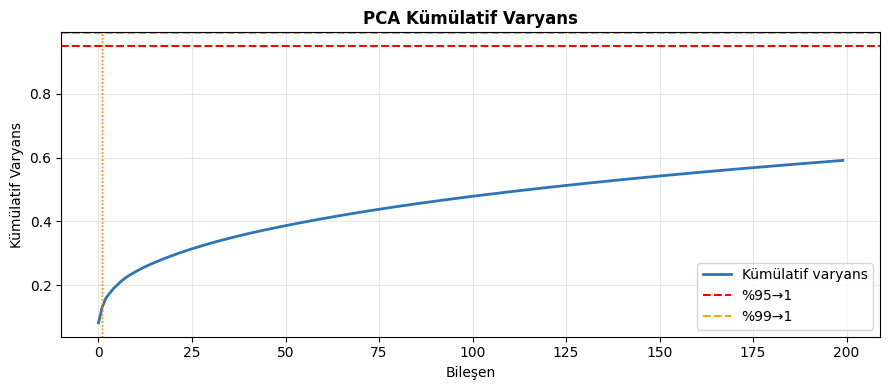

✅ CV'de PCA n_components=0.95 (~1 bileşen) kullanılacak
✅ ML modelleri: ['SVM', 'Random Forest', 'KNN', 'Logistic Regression', 'XGBoost']


In [ ]:
skf=StratifiedKFold(n_splits=N_FOLDS,shuffle=True,random_state=SEED)
ML_MODELS={
    "SVM":SVC(kernel='rbf',C=10,gamma='scale',probability=True,random_state=SEED),
    "Random Forest":RandomForestClassifier(n_estimators=200,max_depth=None,class_weight='balanced',random_state=SEED,n_jobs=-1),
    "KNN":KNeighborsClassifier(n_neighbors=7,weights='distance',metric='euclidean',n_jobs=-1),
    "Logistic Regression":LogisticRegression(C=1.0,solver='lbfgs',max_iter=2000,class_weight='balanced',random_state=SEED,n_jobs=-1),
    "XGBoost":XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=6,subsample=0.8,eval_metric='mlogloss',random_state=SEED,n_jobs=-1,verbosity=0),
}
print("⏳ PCA varyans analizi...")
scaler_tmp=StandardScaler(); X_tmp=scaler_tmp.fit_transform(X_features)
nc_max=min(300,X_features.shape[1])
pca_ex=PCA(n_components=nc_max,random_state=SEED); pca_ex.fit(X_tmp)
cumvar=np.cumsum(pca_ex.explained_variance_ratio_)
n95=int(np.argmax(cumvar>=0.95))+1; n99=int(np.argmax(cumvar>=0.99))+1
print(f"  %95 varyans → {n95} bileşen | %99 varyans → {n99} bileşen")
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(cumvar[:200],lw=2,color='#2E75B6',label='Kümülatif varyans')
ax.axhline(0.95,color='red',ls='--',lw=1.5,label=f'%95→{n95}')
ax.axhline(0.99,color='orange',ls='--',lw=1.5,label=f'%99→{n99}')
ax.axvline(n95,color='red',ls=':',lw=1); ax.axvline(n99,color='orange',ls=':',lw=1)
ax.set_xlabel("Bileşen"); ax.set_ylabel("Kümülatif Varyans")
ax.set_title("PCA Kümülatif Varyans",fontsize=12,fontweight='bold')
ax.legend(); ax.grid(True,alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR,"Yontem3_pca_varyans.png"),dpi=150,bbox_inches='tight')
plt.show()
print(f"✅ CV'de PCA n_components=0.95 (~{n95} bileşen) kullanılacak")
print(f"✅ ML modelleri: {list(ML_MODELS.keys())}")

In [ ]:
all_cv_results=[]
print("="*60)
print("  5-Fold CV Başlıyor — 5 ML Modeli")
print("="*60)
for ml_name,ml_clf in ML_MODELS.items():
    fa,fp,fr,ff=[],[],[],[]; ts=time.time()
    for fi,(tri,tei) in enumerate(skf.split(X_features,y_labels)):
        Xtr=X_features[tri]; Xte=X_features[tei]
        ytr=y_labels[tri];   yte=y_labels[tei]
        sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xte=sc.transform(Xte)
        pc=PCA(n_components=0.95,random_state=SEED); Xtr=pc.fit_transform(Xtr); Xte=pc.transform(Xte)
        clf=copy.deepcopy(ml_clf); clf.fit(Xtr,ytr); yp=clf.predict(Xte)
        fa.append(accuracy_score(yte,yp))
        fp.append(precision_score(yte,yp,average='macro',zero_division=0))
        fr.append(recall_score(yte,yp,average='macro',zero_division=0))
        ff.append(f1_score(yte,yp,average='macro',zero_division=0))
    el=time.time()-ts
    row={'ML Modeli':ml_name,'Accuracy':round(np.mean(fa),4),'Acc Std':round(np.std(fa),4),
         'Precision':round(np.mean(fp),4),'Recall':round(np.mean(fr),4),
         'F1-score':round(np.mean(ff),4),'F1 Std':round(np.std(ff),4),'Train+Test Süresi (sn)':round(el,1)}
    all_cv_results.append(row)
    print(f"  {ml_name:<22} | Acc={row['Accuracy']:.4f}±{row['Acc Std']:.4f} | F1={row['F1-score']:.4f}±{row['F1 Std']:.4f} | {el:.1f}s")
print("\n✅ 5-Fold CV tamamlandı.")

  5-Fold CV Başlıyor — 5 ML Modeli
  SVM                    | Acc=0.6794±0.0204 | F1=0.6808±0.0191 | 281.8s
  Random Forest          | Acc=0.5087±0.0154 | F1=0.5039±0.0144 | 236.3s
  KNN                    | Acc=0.6412±0.0164 | F1=0.6405±0.0152 | 104.1s
  Logistic Regression    | Acc=0.5166±0.0105 | F1=0.5147±0.0110 | 124.7s
  XGBoost                | Acc=0.5606±0.0233 | F1=0.5575±0.0227 | 3656.3s

✅ 5-Fold CV tamamlandı.


💾 CSV: /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/results/Yontem3_karsilastirma.csv

  📊 KARŞILAŞTIRMA TABLOSU — Geleneksel FE + ML | 5-Fold CV
             ML Modeli  Accuracy  Acc Std  Precision  Recall  F1-score  F1 Std  Train+Test Süresi (sn)
1                  SVM    0.6794   0.0204     0.6998  0.6794    0.6808  0.0191                   281.8
2                  KNN    0.6412   0.0164     0.6663  0.6412    0.6405  0.0152                   104.1
3              XGBoost    0.5606   0.0233     0.5743  0.5606    0.5575  0.0227                  3656.3
4  Logistic Regression    0.5166   0.0105     0.5156  0.5166    0.5147  0.0110                   124.7
5        Random Forest    0.5087   0.0154     0.5111  0.5087    0.5039  0.0144                   236.3

🏆 En İyi: SVM  (F1=0.6808)


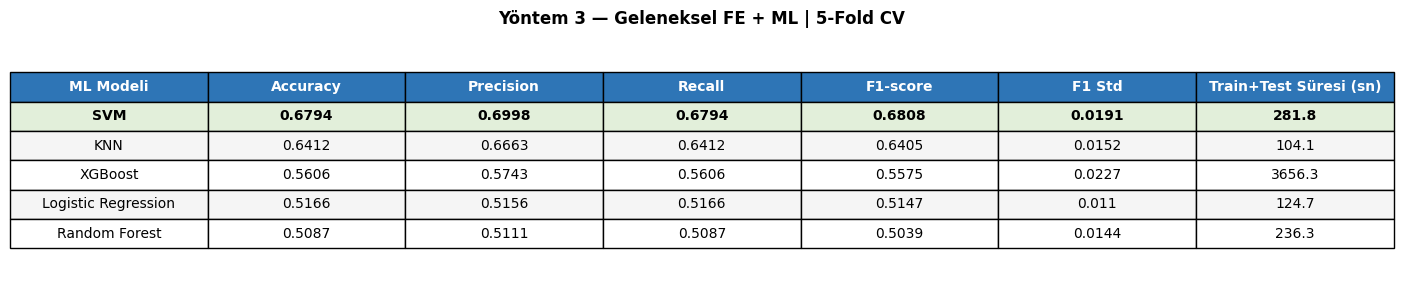

💾 /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/figures/Yontem3_karsilastirma_tablosu.png


In [ ]:
results_df=pd.DataFrame(all_cv_results).sort_values('F1-score',ascending=False).reset_index(drop=True)
results_df.index+=1
best_row=results_df.iloc[0]; best_ml_name=best_row['ML Modeli']; best_f1=best_row['F1-score']
csv_path=os.path.join(RESULTS_DIR,"Yontem3_karsilastirma.csv")
results_df.to_csv(csv_path,index=True); print(f"💾 CSV: {csv_path}")
dcols=['ML Modeli','Accuracy','Acc Std','Precision','Recall','F1-score','F1 Std','Train+Test Süresi (sn)']
print("\n"+"="*70); print("  📊 KARŞILAŞTIRMA TABLOSU — Geleneksel FE + ML | 5-Fold CV"); print("="*70)
print(results_df[dcols].to_string()); print(f"\n🏆 En İyi: {best_ml_name}  (F1={best_f1:.4f})")
scols=['ML Modeli','Accuracy','Precision','Recall','F1-score','F1 Std','Train+Test Süresi (sn)']
td=results_df[scols].copy()
fig,ax=plt.subplots(figsize=(14,3)); ax.axis('off')
tbl=ax.table(cellText=td.values,colLabels=td.columns,loc='center',cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1.2,1.7)
for j in range(len(td.columns)):
    tbl[(0,j)].set_facecolor('#2E75B6'); tbl[(0,j)].set_text_props(color='white',fontweight='bold')
    tbl[(1,j)].set_facecolor('#E2EFDA'); tbl[(1,j)].set_text_props(fontweight='bold')
for i in range(2,len(td)+1):
    bg='#F5F5F5' if i%2==0 else '#FFFFFF'
    for j in range(len(td.columns)): tbl[(i,j)].set_facecolor(bg)
plt.title("Yöntem 3 — Geleneksel FE + ML | 5-Fold CV",fontsize=12,fontweight='bold',pad=12)
plt.tight_layout()
tp=os.path.join(FIGURES_DIR,"Yontem3_karsilastirma_tablosu.png")
plt.savefig(tp,dpi=150,bbox_inches='tight'); plt.show(); print(f"💾 {tp}")

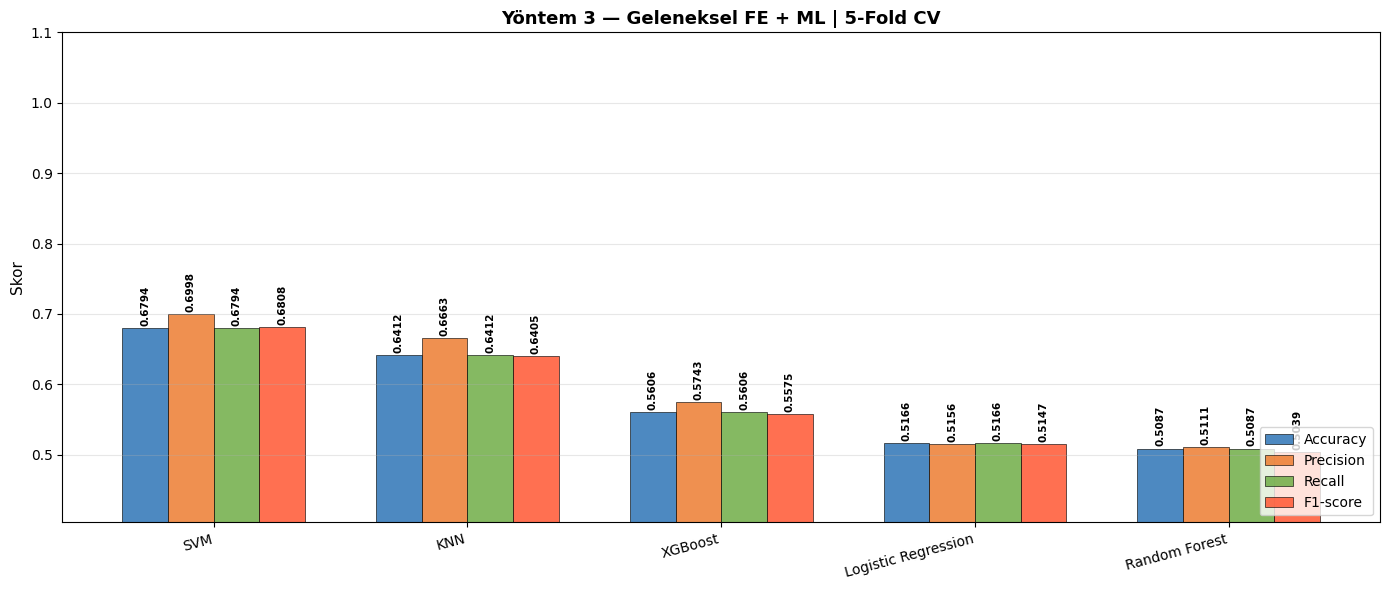

💾 /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/figures/Yontem3_metrik_barlar.png


In [ ]:
metrics=['Accuracy','Precision','Recall','F1-score']
palette=['#2E75B6','#ED7D31','#70AD47','#FF5733']
ml_names=results_df['ML Modeli'].tolist(); n_ml=len(ml_names); bw=0.18; x=np.arange(n_ml)
fig,ax=plt.subplots(figsize=(14,6))
for i,(m,c) in enumerate(zip(metrics,palette)):
    vals=results_df[m].values
    bars=ax.bar(x+i*bw,vals,bw,label=m,color=c,alpha=0.85,edgecolor='black',linewidth=0.5)
    for bar in bars:
        h=bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2,h+0.003,f"{h:.4f}",ha='center',va='bottom',fontsize=7.5,fontweight='bold',rotation=90)
ax.set_xticks(x+bw*1.5); ax.set_xticklabels(ml_names,rotation=15,ha='right',fontsize=10)
ax.set_ylabel('Skor',fontsize=11)
ax.set_ylim(max(0.0,float(results_df[metrics].values.min())-0.1),1.10)
ax.set_title("Yöntem 3 — Geleneksel FE + ML | 5-Fold CV",fontsize=13,fontweight='bold')
ax.legend(loc='lower right',fontsize=10); ax.grid(axis='y',alpha=0.3); plt.tight_layout()
bp=os.path.join(FIGURES_DIR,"Yontem3_metrik_barlar.png")
plt.savefig(bp,dpi=150,bbox_inches='tight'); plt.show(); print(f"💾 {bp}")

🏆 En İyi: SVM  F1=0.6808

  PCA sonrası: 1288 bileşen
⏳ cross_val_predict (5 fold)...
✅ (186.5s)

───────────────────────────────────────────────────────
  Classification Report — SVM
───────────────────────────────────────────────────────
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.77      0.72      0.75       320
   bacterial_leaf_streak       0.88      0.88      0.88       320
bacterial_panicle_blight       0.71      0.83      0.76       320
                   blast       0.67      0.65      0.66       320
              brown_spot       0.71      0.61      0.66       320
              dead_heart       0.67      0.62      0.64       320
            downy_mildew       0.74      0.77      0.76       320
                   hispa       0.65      0.62      0.64       320
                  normal       0.59      0.66      0.62       320
                  tungro       0.58      0.61      0.59       320

                accuracy        

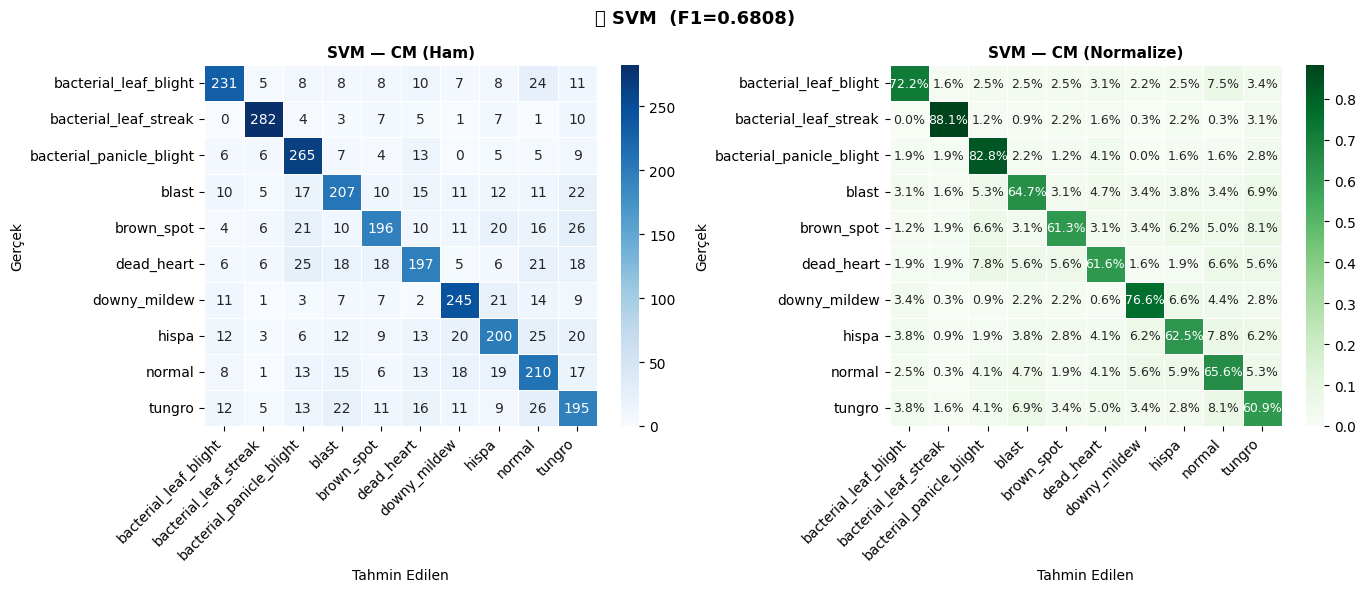

💾 /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/figures/Yontem3_enIyi_cm.png


In [ ]:
print(f"🏆 En İyi: {best_ml_name}  F1={best_f1:.4f}\n")
scf=StandardScaler(); Xs=scf.fit_transform(X_features)
pcf=PCA(n_components=0.95,random_state=SEED); Xp=pcf.fit_transform(Xs)
print(f"  PCA sonrası: {Xp.shape[1]} bileşen")
clf_best=copy.deepcopy(ML_MODELS[best_ml_name])
print(f"⏳ cross_val_predict ({N_FOLDS} fold)..."); t0=time.time()
y_pred_all=cross_val_predict(clf_best,Xp,y_labels,cv=skf,n_jobs=-1)
print(f"✅ ({time.time()-t0:.1f}s)\n")
print("─"*55); print(f"  Classification Report — {best_ml_name}"); print("─"*55)
print(classification_report(y_labels,y_pred_all,target_names=CLASS_NAMES,zero_division=0))
fig,axes=plt.subplots(1,2,figsize=(2*max(7,NUM_CLASSES*0.65),max(6,NUM_CLASSES*0.6)))
cm_abs=confusion_matrix(y_labels,y_pred_all)
sns.heatmap(cm_abs,annot=True,fmt='d',cmap='Blues',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,linewidths=0.5,ax=axes[0],annot_kws={'size':10})
axes[0].set_title(f"{best_ml_name} — CM (Ham)",fontsize=11,fontweight='bold')
axes[0].set_xlabel('Tahmin Edilen'); axes[0].set_ylabel('Gerçek')
cm_norm=cm_abs.astype('float')/cm_abs.sum(axis=1)[:,np.newaxis]
sns.heatmap(cm_norm,annot=True,fmt='.1%',cmap='Greens',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,linewidths=0.5,ax=axes[1],annot_kws={'size':9})
axes[1].set_title(f"{best_ml_name} — CM (Normalize)",fontsize=11,fontweight='bold')
axes[1].set_xlabel('Tahmin Edilen'); axes[1].set_ylabel('Gerçek')
for a in axes:
    a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right'); a.set_yticklabels(a.get_yticklabels(),rotation=0)
plt.suptitle(f"🏆 {best_ml_name}  (F1={best_f1:.4f})",fontsize=13,fontweight='bold')
plt.tight_layout()
cmp=os.path.join(FIGURES_DIR,"Yontem3_enIyi_cm.png")
plt.savefig(cmp,dpi=150,bbox_inches='tight'); plt.show(); print(f"💾 {cmp}")

⏳ RF özellik önem analizi...
✅ (70.1s)

📊 FE Grup Önem:
         FE Yöntemi  Toplam Önem  Boyut
HOG (Gradyan/Kenar)     0.950855   8100
        GLCM (Doku)     0.020762     24
 LBP (Yerel Örüntü)     0.011490     10
  Piksel İstatistik     0.004937      4
   Canny İstatistik     0.004895      4
  Wavelet (Frekans)     0.004068      4
 Hu Moments (Şekil)     0.002993      7


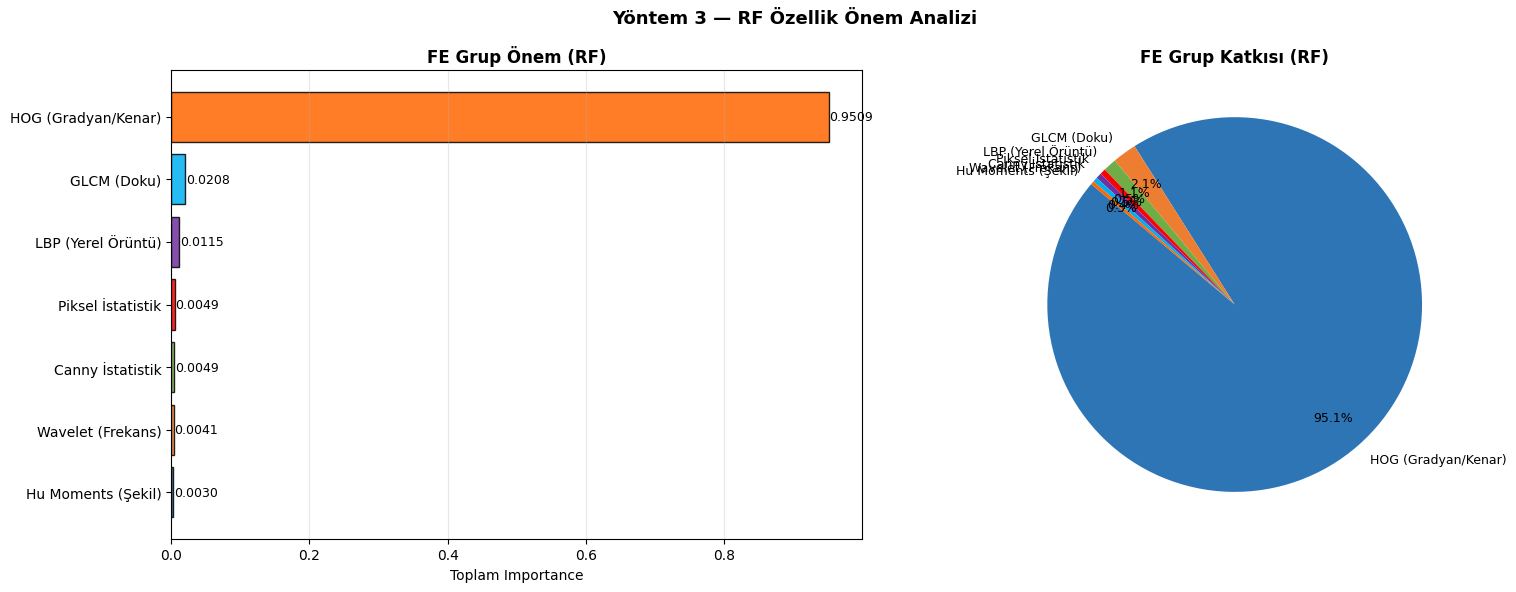

💾 /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/figures/Yontem3_grup_onem.png


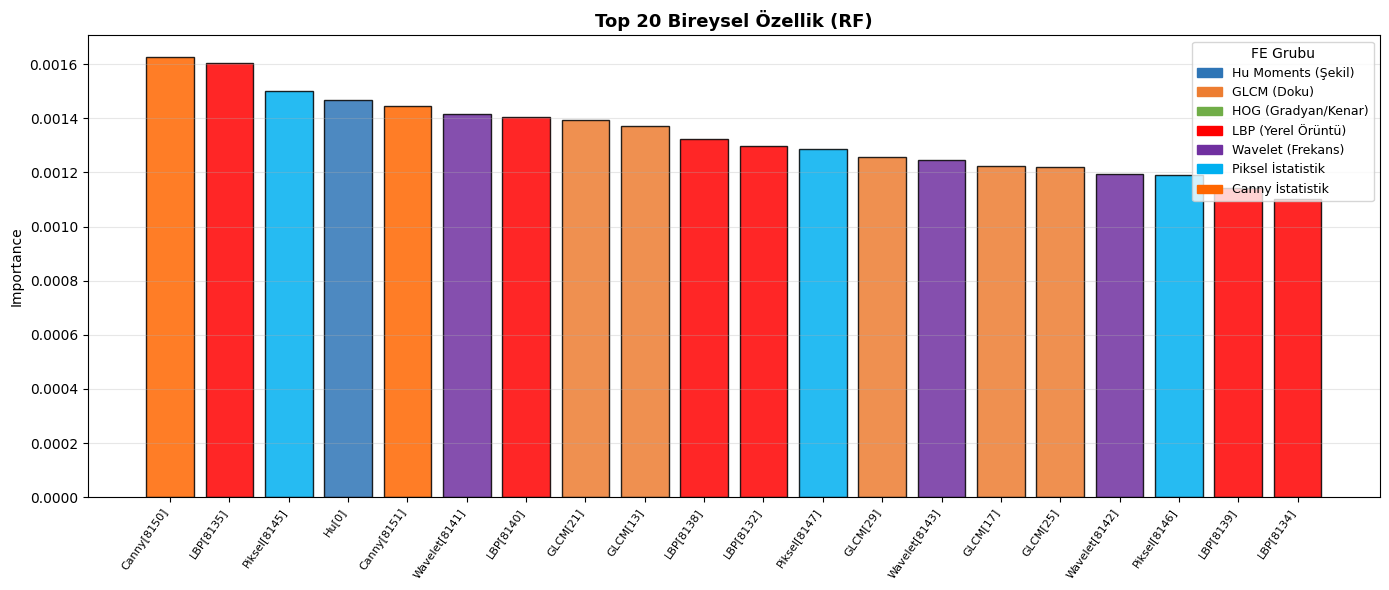

💾 /content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem3/figures/Yontem3_top20_onem.png


In [ ]:
print("⏳ RF özellik önem analizi..."); t0=time.time()
scrf=StandardScaler(); Xrf=scrf.fit_transform(X_features)
rf_imp=RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=SEED,n_jobs=-1)
rf_imp.fit(Xrf,y_labels); imps=rf_imp.feature_importances_
print(f"✅ ({time.time()-t0:.1f}s)")
fe_groups={}; st=0
for n,dd in FE_DIMS.items(): fe_groups[n]=(st,st+dd); st+=dd
gimp={n:imps[s:e].sum() for n,(s,e) in fe_groups.items()}
gdf=pd.DataFrame({'FE Yöntemi':list(gimp.keys()),'Toplam Önem':list(gimp.values()),'Boyut':list(FE_DIMS.values())}).sort_values('Toplam Önem',ascending=False).reset_index(drop=True)
print("\n📊 FE Grup Önem:"); print(gdf.to_string(index=False))
cb=['#2E75B6','#ED7D31','#70AD47','#FF0000','#7030A0','#00B0F0','#FF6600']
fig,axes=plt.subplots(1,2,figsize=(16,6))
bars=axes[0].barh(gdf['FE Yöntemi'][::-1],gdf['Toplam Önem'][::-1],color=cb[:len(gdf)],alpha=0.85,edgecolor='black')
axes[0].set_xlabel('Toplam Importance'); axes[0].set_title('FE Grup Önem (RF)',fontweight='bold'); axes[0].grid(axis='x',alpha=0.3)
for bar in bars:
    w=bar.get_width(); axes[0].text(w+0.001,bar.get_y()+bar.get_height()/2,f"{w:.4f}",va='center',fontsize=9)
axes[1].pie(gdf['Toplam Önem'],labels=gdf['FE Yöntemi'],autopct='%1.1f%%',colors=cb[:len(gdf)],startangle=140,pctdistance=0.8,textprops={'fontsize':9})
axes[1].set_title('FE Grup Katkısı (RF)',fontweight='bold')
plt.suptitle('Yöntem 3 — RF Özellik Önem Analizi',fontsize=13,fontweight='bold')
plt.tight_layout()
gip=os.path.join(FIGURES_DIR,"Yontem3_grup_onem.png")
plt.savefig(gip,dpi=150,bbox_inches='tight'); plt.show(); print(f"💾 {gip}")
# Top-20
def get_group(fi):
    for n,(s,e) in fe_groups.items():
        if s<=fi<e: return n
    return 'Bilinmeyen'
gcm=dict(zip(FE_DIMS.keys(),cb)); tk=20
ti=np.argsort(imps)[::-1][:tk]
tl=[f"{get_group(i).split(' ')[0]}[{i}]" for i in ti]; tv=imps[ti]
tc=[gcm.get(get_group(i),'#888') for i in ti]
fig,ax=plt.subplots(figsize=(14,6))
ax.bar(range(tk),tv,color=tc,alpha=0.85,edgecolor='black')
ax.set_xticks(range(tk)); ax.set_xticklabels(tl,rotation=55,ha='right',fontsize=8)
ax.set_ylabel('Importance'); ax.set_title(f'Top {tk} Bireysel Özellik (RF)',fontsize=13,fontweight='bold'); ax.grid(axis='y',alpha=0.3)
ax.legend(handles=[Patch(color=c,label=n) for n,c in gcm.items()],loc='upper right',fontsize=9,title='FE Grubu')
plt.tight_layout()
tip=os.path.join(FIGURES_DIR,"Yontem3_top20_onem.png")
plt.savefig(tip,dpi=150,bbox_inches='tight'); plt.show(); print(f"💾 {tip}")

  FINAL — Yöntem 1 vs 2 vs 3
  Yöntem                  Açıklama  Accuracy  Precision  Recall  F1-score       CV
Yöntem 2 DL FE (DenseNet121) + SVM    0.8975     0.8989  0.8975    0.8973   5-Fold
Yöntem 1           DL (ResNet50V2)    0.7219     0.7256  0.7219    0.7221 Hold-out
Yöntem 3       Geleneksel FE + SVM    0.6794     0.6998  0.6794    0.6808   5-Fold


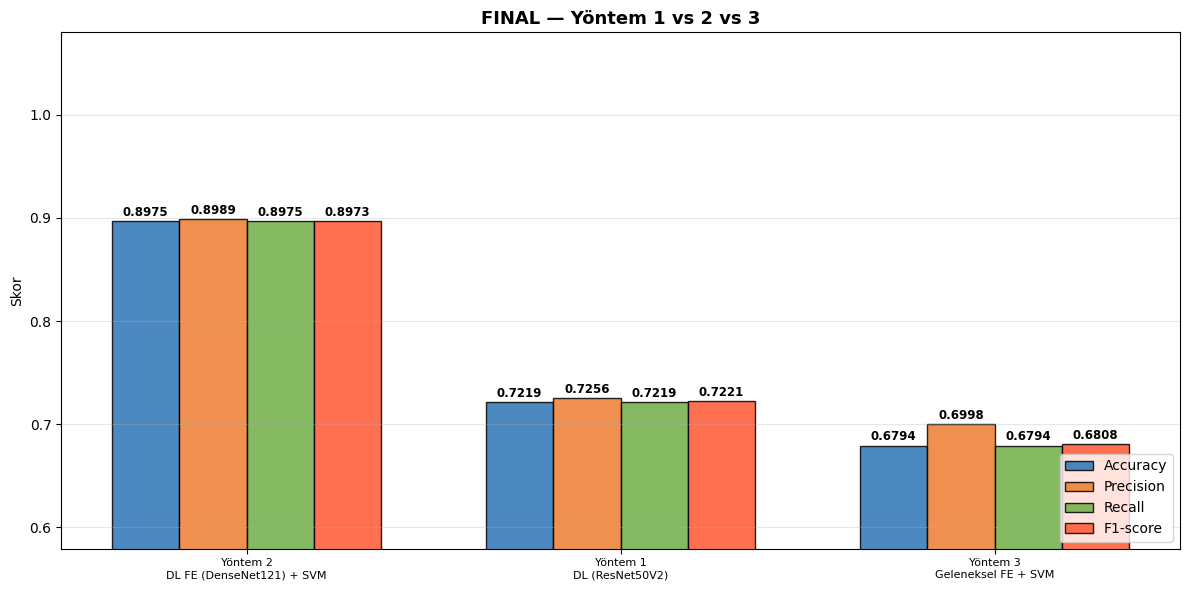

💾 Final CSV kaydedildi.


In [ ]:
y1_csv = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/results/Yontem1_karsilastirma.csv"
y2_csv = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem2/results/Yontem2_karsilastirma.csv"

def _read_csv_safe(path, name_col):
    """CSV'yi oku; isim sütunu yanlışlıkla index'e düştüyse geri al."""
    df = pd.read_csv(path)
    if name_col not in df.columns:           # index_col olarak kaydedilmiş olabilir
        df = df.reset_index()
    return df

rows = []
y3b = results_df.iloc[0]
rows.append({'Yöntem':'Yöntem 3','Açıklama':f"Geleneksel FE + {y3b['ML Modeli']}",
             'Accuracy':y3b['Accuracy'],'Precision':y3b['Precision'],
             'Recall':y3b['Recall'],'F1-score':y3b['F1-score'],'CV':'5-Fold'})

if os.path.exists(y1_csv):
    y1df = _read_csv_safe(y1_csv, 'Model')
    y1b  = y1df.sort_values('F1-score', ascending=False).iloc[0]
    rows.append({'Yöntem':'Yöntem 1','Açıklama':f"DL ({y1b['Model']})",
                 'Accuracy':y1b['Accuracy'],'Precision':y1b['Precision'],
                 'Recall':y1b['Recall'],'F1-score':y1b['F1-score'],'CV':'Hold-out'})
else:
    print("⚠️  Yöntem 1 CSV yok:", y1_csv)

if os.path.exists(y2_csv):
    y2df = _read_csv_safe(y2_csv, 'DL Modeli')
    y2b  = y2df.sort_values('F1-score', ascending=False).iloc[0]
    rows.append({'Yöntem':'Yöntem 2','Açıklama':f"DL FE ({y2b['DL Modeli']}) + {y2b['ML Modeli']}",
                 'Accuracy':y2b['Accuracy'],'Precision':y2b['Precision'],
                 'Recall':y2b['Recall'],'F1-score':y2b['F1-score'],'CV':'5-Fold'})
else:
    print("⚠️  Yöntem 2 CSV yok:", y2_csv)

fdf = pd.DataFrame(rows).sort_values('F1-score', ascending=False).reset_index(drop=True)
print("="*72); print("  FINAL — Yöntem 1 vs 2 vs 3"); print("="*72)
print(fdf.to_string(index=False))

if len(fdf) > 1:
    mf=['Accuracy','Precision','Recall','F1-score']; pf=['#2E75B6','#ED7D31','#70AD47','#FF5733']
    bwf=0.18; xf=np.arange(len(fdf))
    fig,ax=plt.subplots(figsize=(12,6))
    for i,(m,c) in enumerate(zip(mf,pf)):
        bars=ax.bar(xf+i*bwf,fdf[m].values,bwf,label=m,color=c,alpha=0.85,edgecolor='black')
        for bar in bars:
            h=bar.get_height(); ax.text(bar.get_x()+bar.get_width()/2,h+0.002,f"{h:.4f}",ha='center',va='bottom',fontsize=8.5,fontweight='bold')
    ax.set_xticks(xf+bwf*1.5)
    ax.set_xticklabels([f"{r['Yöntem']}\n{r['Açıklama']}" for _,r in fdf.iterrows()],fontsize=8,ha='center')
    ax.set_ylim(max(0.0,float(fdf[mf].values.min())-0.1),1.08)
    ax.set_ylabel('Skor'); ax.set_title('FINAL — Yöntem 1 vs 2 vs 3',fontsize=13,fontweight='bold')
    ax.legend(loc='lower right'); ax.grid(axis='y',alpha=0.3); plt.tight_layout()
    fp=os.path.join(FIGURES_DIR,"Yontem3_final_karsilastirma.png")
    plt.savefig(fp,dpi=150,bbox_inches='tight'); plt.show()

fdf.to_csv(os.path.join(RESULTS_DIR,"Yontem3_final_3yontem.csv"), index=False)
print("💾 Final CSV kaydedildi.")

In [ ]:
print("="*65); print("  YÖNTEM 3 — TAMAMLANDI ✅"); print("="*65)
print("\n📁 Özellik dosyaları:")
for f in sorted(os.listdir(FEATURES_DIR)): print(f"  ✅ {f}  ({os.path.getsize(os.path.join(FEATURES_DIR,f))/1e6:.1f} MB)")
print("\n📁 Grafikler:")
for f in sorted(os.listdir(FIGURES_DIR)): print(f"  📊 {f}")
print("\n📁 Sonuçlar:")
for f in sorted(os.listdir(RESULTS_DIR)): print(f"  📋 {f}")
print("\n"+"="*65); print("  📊 YÖNTEM 3 SONUÇLAR:"); print("="*65)
print(results_df[['ML Modeli','Accuracy','Precision','Recall','F1-score','Train+Test Süresi (sn)']].to_string())
print(f"\n🏆 En İyi : {best_ml_name}  F1={best_f1:.4f}"); print("="*65)

  YÖNTEM 3 — TAMAMLANDI ✅

📁 Özellik dosyaları:
  ✅ Yontem3_features_handcrafted.npy  (104.4 MB)
  ✅ Yontem3_labels.npy  (0.0 MB)

📁 Grafikler:
  📊 Yontem3_enIyi_cm.png
  📊 Yontem3_fe_gorsel.png
  📊 Yontem3_final_karsilastirma.png
  📊 Yontem3_grup_onem.png
  📊 Yontem3_karsilastirma_tablosu.png
  📊 Yontem3_metrik_barlar.png
  📊 Yontem3_onisleme.png
  📊 Yontem3_pca_varyans.png
  📊 Yontem3_top20_onem.png

📁 Sonuçlar:
  📋 Yontem3_final_3yontem.csv
  📋 Yontem3_karsilastirma.csv

  📊 YÖNTEM 3 SONUÇLAR:
             ML Modeli  Accuracy  Precision  Recall  F1-score  Train+Test Süresi (sn)
1                  SVM    0.6794     0.6998  0.6794    0.6808                   281.8
2                  KNN    0.6412     0.6663  0.6412    0.6405                   104.1
3              XGBoost    0.5606     0.5743  0.5606    0.5575                  3656.3
4  Logistic Regression    0.5166     0.5156  0.5166    0.5147                   124.7
5        Random Forest    0.5087     0.5111  0.5087    0.5039       